# The global gradient algorithm (GGA)

Exploration notebook for Phase 3. It writes out the formulation behind `wdtk.network.gga.solve_gga`, which is the Todini and Pilati (1987) method that EPANET uses, and runs it step by step on the two-loop test network.

## 1. Unknowns and governing equations

A network has $n_j$ junctions (unknown head $H_i$, known demand $q_i$), $n_0$ reservoirs (known head $H_{0}$) and $n_l$ links (unknown flow $Q_k$, positive from the link's start node to its end node).

**Energy, one equation per link.** The head drop along link $k$ equals the head loss:

$$h_k(Q_k) = H_{\text{start}(k)} - H_{\text{end}(k)}$$

The head-loss laws used here, with $h$ carrying the sign of $Q$:

| Link | $h_k(Q)$ | $\partial h_k / \partial Q$ |
|---|---|---|
| Hazen-Williams pipe | $r Q\lvert Q\rvert^{n-1} + m Q\lvert Q\rvert$ | $n r \lvert Q\rvert^{n-1} + 2 m \lvert Q\rvert$ |
| Darcy-Weisbach pipe | $\left(f \tfrac{L}{D} + K\right)\dfrac{Q\lvert Q\rvert}{2 g A^2}$ | $\approx 2 h / Q$ ($f$ held fixed) |
| Pump, $H = a - bQ^c$ | $-(a - b Q\lvert Q\rvert^{c-1})$ | $c\, b \lvert Q\rvert^{c-1}$ |

Here $m = K/(2gA^2)$ accounts for minor losses. All the gradients are positive.

**Continuity, one equation per junction.** Inflow minus outflow equals demand.

## 2. Matrix form

Define the incidence matrices $A_{12}$ ($n_l \times n_j$) and $A_{10}$ ($n_l \times n_0$). Each has $-1$ where a link starts at a node and $+1$ where it ends. Then

$$
\underbrace{h(Q) + A_{12} H + A_{10} H_0}_{F_1(Q,\,H)} = 0, \qquad
\underbrace{A_{21} Q - q}_{F_2(Q)} = 0, \qquad A_{21} = A_{12}^{T}.
$$

## 3. Newton linearization

With $D = \operatorname{diag}(\partial h_k / \partial Q_k)$, one Newton step solves

$$
\begin{bmatrix} D & A_{12} \\ A_{21} & 0 \end{bmatrix}
\begin{bmatrix} \Delta Q \\ \Delta H \end{bmatrix}
= -\begin{bmatrix} F_1 \\ F_2 \end{bmatrix}.
$$

## 4. Schur complement: solve for heads first

The first block row gives $\Delta Q = -D^{-1}(F_1 + A_{12}\Delta H)$. Substituting into the second row eliminates $\Delta Q$:

$$
\left(A_{21} D^{-1} A_{12}\right)\Delta H = F_2 - A_{21} D^{-1} F_1 .
$$

The matrix $A_{21} D^{-1} A_{12} = A_{12}^{T} D^{-1} A_{12}$ is **symmetric** by construction. It is **positive definite** because $D^{-1} > 0$ and $A_{12}$ has full column rank whenever every junction is connected to a reservoir. Its sparsity matches the junction adjacency: entry $(i, j)$ is nonzero only if a link joins junctions $i$ and $j$. So each iteration costs one sparse SPD solve of size $n_j$. Flows are then updated link by link.

Because $F_2$ is linear in $Q$, continuity holds exactly after the first iteration. The remaining iterations only fix the energy equations.

## 5. Convergence and regularization

* **Stopping rule:** stop when $\sum\lvert\Delta Q\rvert / \sum\lvert Q\rvert$ falls below the accuracy, EPANET's criterion (EPANET's default is $10^{-3}$; validation here uses $10^{-6}$).
* **Zero-flow links:** gradients are evaluated at $\max(\lvert Q\rvert, 10^{-6}\ \text{m}^3/\text{s})$, so $D$ stays invertible at zero flow. The residuals $F_1$ use the exact $h(Q)$, so this changes the path of the iteration, not the converged answer.
* **Convergence rate:** Hazen-Williams and pump laws get exact Newton gradients, so convergence is quadratic. For Darcy-Weisbach, holding $f$ fixed drops the $\partial f / \partial Q$ term, so convergence is linear but still fast (see `reports/phase3/convergence.png`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp

from wdtk import plotting
from wdtk.network.gga import solve_gga
from wdtk.network.hydraulics import HydraulicOptions, link_headloss
from wdtk.network.io import read_inp

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
plotting.apply_style()
net = read_inp(ROOT / "data" / "networks" / "two_loop_hw.inp")
A12, A10 = net.incidence
links = [lk.id for lk in net.links]
juncs = [j.id for j in net.junctions]
print(f"{len(juncs)} junctions, {len(net.reservoirs)} reservoir, {len(links)} links")
pd.DataFrame(A12.toarray().astype(int), index=links, columns=juncs)

6 junctions, 1 reservoir, 8 links


,J1,J2,J3,J4,J5,J6
P1,1,0,0,0,0,0
P2,-1,1,0,0,0,0
P3,0,-1,1,0,0,0
P4,-1,0,0,1,0,0
P5,0,-1,0,0,1,0
P6,0,0,-1,0,0,1
P7,0,0,0,-1,1,0
P8,0,0,0,0,-1,1


## 6. Structure of the head system on the two-loop network

The incidence matrix (left) has two nonzeros per row for a pipe between junctions, and one for the pipe from the reservoir. The Schur complement $A_{21} D^{-1} A_{12}$ (right) is a weighted graph Laplacian of the junctions. It has a nonzero wherever two junctions share a pipe.

Schur complement symmetric: True
Eigenvalues (all positive => SPD): min 1.423e-03, max 6.824e-02


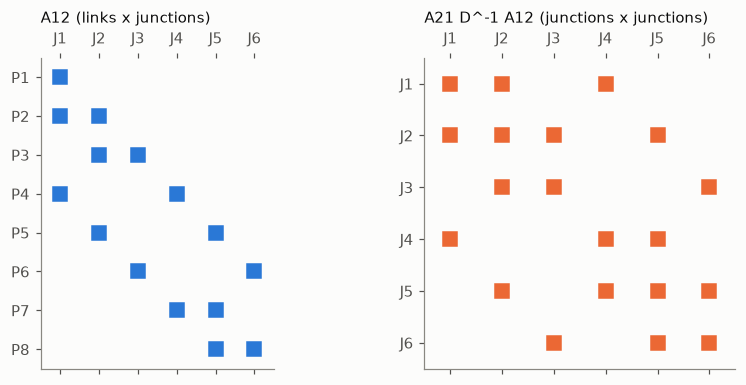

In [2]:
res = solve_gga(net)
_, grad = link_headloss(net, res.flows_m3s, HydraulicOptions())
schur = (A12.T @ sp.diags_array(1.0 / grad) @ A12).toarray()
eig = np.linalg.eigvalsh(schur)
print("Schur complement symmetric:", np.allclose(schur, schur.T))
print(f"Eigenvalues (all positive => SPD): min {eig.min():.3e}, max {eig.max():.3e}")

fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.6))
axes[0].spy(A12.toarray(), markersize=9, color=plotting.CATEGORICAL[0])
axes[0].set_title("A12 (links x junctions)", fontsize=10, loc="left")
axes[0].set_yticks(range(len(links)), labels=links)
axes[0].set_xticks(range(len(juncs)), labels=juncs)
axes[1].spy(schur, markersize=9, color=plotting.CATEGORICAL[1])
axes[1].set_title("A21 D^-1 A12 (junctions x junctions)", fontsize=10, loc="left")
axes[1].set_xticks(range(len(juncs)), labels=juncs)
axes[1].set_yticks(range(len(juncs)), labels=juncs)
for ax in axes:
    ax.grid(False)
fig.tight_layout()
plt.show()

## 7. Iteration history on the two-loop network

In [3]:
res_tight = solve_gga(net, accuracy=1e-12)
pd.DataFrame(
    {
        "relative flow change (-)": [r.relative_flow_change for r in res_tight.history],
        "max |dQ| (L/s)": [r.max_flow_change_m3s * 1000 for r in res_tight.history],
        "max energy residual (m)": [r.max_head_imbalance_m for r in res_tight.history],
        "max continuity residual (L/s)": [
            r.max_continuity_residual_m3s * 1000 for r in res_tight.history
        ],
    },
    index=pd.Index([r.iteration for r in res_tight.history], name="iteration"),
).style.format("{:.2e}")

,relative flow change (-),max |dQ| (L/s),max energy residual (m),max continuity residual (L/s)
iteration,,,,
1,6.88e-01,1.22e+02,2.74e+00,4.72e-12
2,1.43e-02,1.62e+00,6.32e-02,1.04e-14
3,5.91e-04,6.72e-02,1.07e-04,8.67e-15
4,9.97e-07,1.13e-04,3.05e-10,6.94e-15
5,2.85e-12,3.24e-10,1.73e-14,8.67e-15
6,8.83e-17,1.91e-14,1.67e-14,1.91e-14


The relative flow change roughly squares at each iteration (quadratic convergence), and the continuity residual sits at round-off level from the first iteration on, as Section 4 predicts.

In [4]:
pd.DataFrame(
    {
        "head (m)": res.heads_m,
        "pressure head (m)": res.pressures_m,
    },
    index=pd.Index(juncs, name="junction"),
).style.format("{:.3f}")

,head (m),pressure head (m)
junction,,
J1,207.237,57.237
J2,203.082,48.082
J3,196.778,36.778
J4,204.516,59.516
J5,199.110,49.110
J6,195.419,43.419
